In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [26]:
fake_df = pd.read_csv("../dataset/Fake.csv")
real_df = pd.read_csv("../dataset/True.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [27]:
print("Fake News Dataset:", fake_df.shape)
print("Real News Dataset:", real_df.shape)

Fake News Dataset: (23481, 4)
Real News Dataset: (21417, 4)


In [28]:
print("Fake News Columns:")
print(fake_df.columns.tolist())

print("\nReal News Columns:")
print(real_df.columns.tolist())

Fake News Columns:
['title', 'text', 'subject', 'date']

Real News Columns:
['title', 'text', 'subject', 'date']


In [29]:
fake_df.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [30]:
real_df.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [31]:
fake_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    23481 non-null  str  
 1   text     23481 non-null  str  
 2   subject  23481 non-null  str  
 3   date     23481 non-null  str  
dtypes: str(4)
memory usage: 733.9 KB


In [32]:
real_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    21417 non-null  str  
 1   text     21417 non-null  str  
 2   subject  21417 non-null  str  
 3   date     21417 non-null  str  
dtypes: str(4)
memory usage: 669.4 KB


In [35]:
print("Missing Values in Fake News:")
print(fake_df.isnull().sum())

print("Missing values in Real News:")
print(real_df.isnull().sum())

Missing Values in Fake News:
title      0
text       0
subject    0
date       0
dtype: int64
Missing values in Real News:
title      0
text       0
subject    0
date       0
dtype: int64


In [36]:
print("Fake duplicate rows:", fake_df.duplicated().sum())
print("Real duplicate rows:", real_df.duplicated().sum())

Fake duplicate rows: 3
Real duplicate rows: 206


In [37]:
fake_df["label"] = 0
real_df["label"] = 1

In [38]:
fake_df.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [39]:
real_df.head()

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [40]:
df = pd.concat(
    [fake_df, real_df],
    ignore_index = True
)

In [42]:
print("Combined dataset shape:",df.shape)

Combined dataset shape: (44898, 5)


In [44]:
df = df.sample(
    frac = 1,
    random_state = 42
).reset_index(drop = True)

In [45]:
df.head()

,title,text,subject,date,label
0,It’s Really Happening: Trump Adviser Lays Out...,"Well, that didn t take long. In the short time...",News,"November 16, 2016",0
1,Republican attempt to deflect Trump-Russia pro...,(Reuters) - Republican lawmaker Devin Nunes’ i...,politicsNews,"September 11, 2017",1
2,Trump says churches should get FEMA funds for ...,WASHINGTON (Reuters) - President Donald Trump ...,politicsNews,"September 9, 2017",1
3,Trump Loves To Say The New York Times Is ‘Fai...,Print journalism and longstanding papers have ...,News,"August 7, 2017",0
4,House Speaker Ryan briefed Trump on healthcare...,WASHINGTON (Reuters) - President Donald Trump ...,politicsNews,"March 24, 2017",1


In [46]:
print(df["label"].value_counts())

label
0    23481
1    21417
Name: count, dtype: int64


In [47]:
print(df["label"].value_counts(normalize = True) * 100)

label
0    52.298543
1    47.701457
Name: proportion, dtype: float64


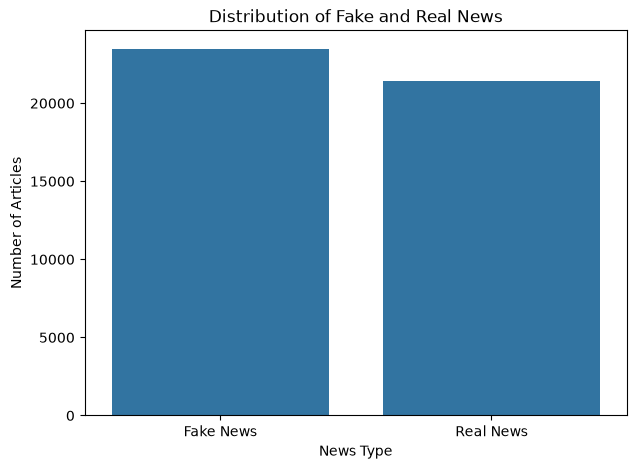

In [48]:
plt.figure(figsize = (7, 5))


sns.countplot(
    x = "label",
    data = df
)

plt.title("Distribution of Fake and Real News")
plt.xlabel("News Type")
plt.ylabel("Number of Articles")

plt.xticks(
    [0, 1],
    ["Fake News", "Real News"]
)

plt.show()

In [49]:
print(df["subject"].value_counts())

subject
politicsNews       11272
worldnews          10145
News                9050
politics            6841
left-news           4459
Government News     1570
US_News              783
Middle-east          778
Name: count, dtype: int64


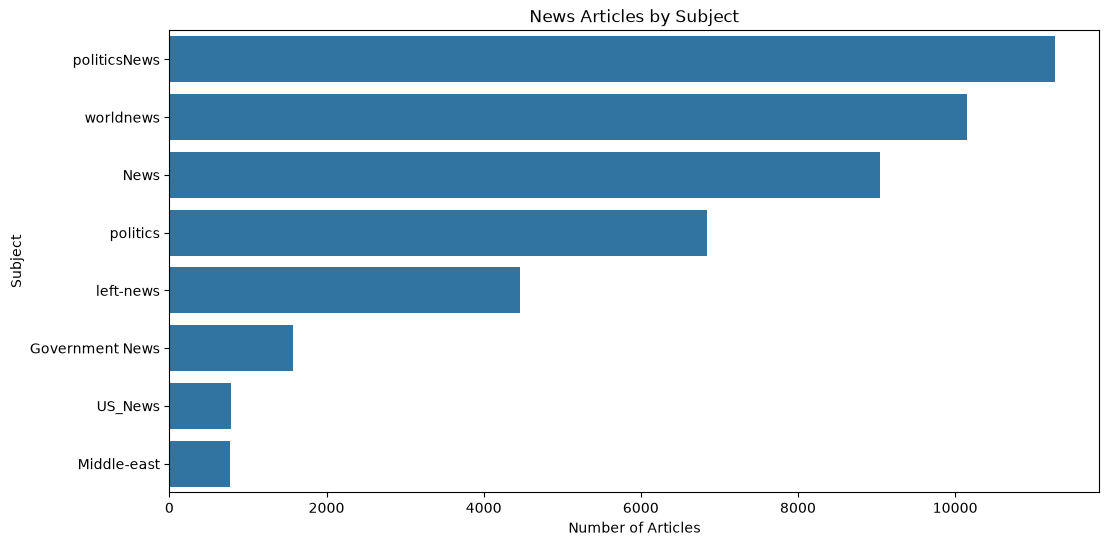

In [50]:
plt.figure(figsize = (12,6))


sns.countplot(
    y = "subject",
    data = df,
    order = df["subject"].value_counts().index
)

plt.title("News Articles by Subject")
plt.xlabel("Number of Articles")
plt.ylabel("Subject")

plt.show()

In [51]:
df["text_length"] = df["text"].fillna("").str.len()

In [52]:
df["text_length"].describe()

count    44898.000000
mean      2469.109693
std       2171.617091
min          1.000000
25%       1234.000000
50%       2186.000000
75%       3105.000000
max      51794.000000
Name: text_length, dtype: float64

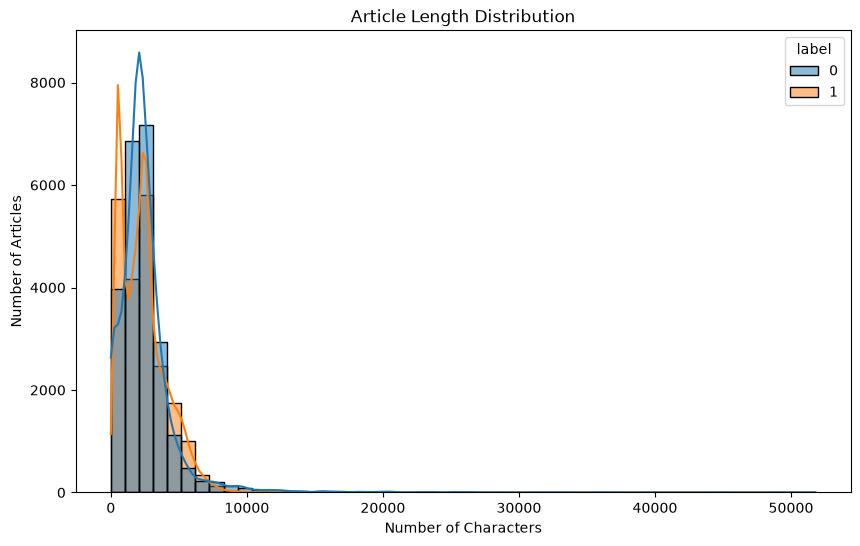

In [53]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="text_length",
    hue="label",
    bins=50,
    kde=True
)

plt.title("Article Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Articles")

plt.show()

In [55]:
fake_sample = df[df["label"] == 0].iloc[0]

print("TITLE:")
print(fake_sample["title"])

print("\nARTICLE:")
print(fake_sample["text"])

TITLE:
 It’s Really Happening: Trump Adviser Lays Out Plan For National Muslim Registry

ARTICLE:
Well, that didn t take long. In the short time since Americans kinda-sorta elected Donald Trump to be Pussygrabber-in-Chief, Trump has appointed a bona fide white nationalist to a high-level position and perform numerous other actions that months ago were considered extremely unlikely nightmare scenarios   and the latest seems to be that the Muslim registry the media told us Trump was not serious about might actually happen.Under the Trump regime, Muslim immigrants coming to the United States from what Trump and Pals call  terror-prone  countries will soon have to register and check in regularly with the government if Trump adviser and Kansas Secretary of State, Kris Kobach, has his way.Kobach says that the Trump administration aims to quickly waste taxpayer dollars on The Wall and that they are moving forward on a proposal to get things rolling with a registry for immigrants from Muslim c

In [56]:
real_sample = df[df["label"] == 1].iloc[0]

print("TITLE:")
print(fake_sample["title"])

print("\nARTICLE:")
print(real_sample["text"])

TITLE:
 It’s Really Happening: Trump Adviser Lays Out Plan For National Muslim Registry

ARTICLE:
(Reuters) - Republican lawmaker Devin Nunes’ investigation into whether Obama administration officials used classified intelligence reports to discredit Donald Trump’s 2016 campaign team could backfire on the congressman - and the president, sources familiar with the reports said. The reports contain no evidence that any aides to former Democratic President Barack Obama acted improperly, the sources said, but they do indicate some Trump associates may have violated an obscure 1799 law, the Logan Act, which prohibits unauthorized U.S. citizens from negotiating with a foreign government that has a dispute with the United States. The spying reports also are relevant to the investigation by special counsel Robert Mueller into conclusions by U.S. intelligence agencies that Russia worked to tilt last November’s election in Republican Trump’s favor, said the sources, who spoke on the condition of

In [58]:
df = df.drop(columns = ["text_length"])

In [59]:
df.to_csv(
    "../dataset/news_dataset.csv",
    index = False
)

In [60]:
print("Final dataset shape:", df.shape)

Final dataset shape: (44898, 5)


In [61]:
df.head()

,title,text,subject,date,label
0,It’s Really Happening: Trump Adviser Lays Out...,"Well, that didn t take long. In the short time...",News,"November 16, 2016",0
1,Republican attempt to deflect Trump-Russia pro...,(Reuters) - Republican lawmaker Devin Nunes’ i...,politicsNews,"September 11, 2017",1
2,Trump says churches should get FEMA funds for ...,WASHINGTON (Reuters) - President Donald Trump ...,politicsNews,"September 9, 2017",1
3,Trump Loves To Say The New York Times Is ‘Fai...,Print journalism and longstanding papers have ...,News,"August 7, 2017",0
4,House Speaker Ryan briefed Trump on healthcare...,WASHINGTON (Reuters) - President Donald Trump ...,politicsNews,"March 24, 2017",1


In [62]:
df.tail()

,title,text,subject,date,label
44893,Trump Just FAILED Hundreds Of Manufacturing W...,"Last year, Trump claimed he was succeeding at ...",News,"May 7, 2017",0
44894,Judge Garland not interested in FBI job: sources,WASHINGTON (Reuters) - U.S. appeals court judg...,politicsNews,"May 16, 2017",1
44895,Expert On Voting Fraud DESTROYS Trump’s Lies ...,Terrified and unable to accept that he s destr...,News,"October 17, 2016",0
44896,[Video] POLICE HAVE VERY GOOD REASON FOR BLOCK...,This mayor s involvement in potential illegal ...,politics,"Apr 24, 2015",0
44897,BUSTED! WASHINGTON POST Skips Maxine Waters’ A...,There are 20 Democrats who at certain times ha...,politics,"May 10, 2017",0


In [63]:
df["label"].value_counts()

label
0    23481
1    21417
Name: count, dtype: int64

In [64]:
print(df.isnull().sum())

title      0
text       0
subject    0
date       0
label      0
dtype: int64
